# PC6 - Parte 2
Se dispone de la fracción quemada mensual en el norte de Bolivia (Beni) y la zona centro-oriental de Perú (Ucayali), en la grilla de 0.25°, según tres fuentes: el modelo Sparky, 
Sentinel-2 (dNBR) y MapBiomas Fuego. Se asigna una ventana de tres meses (jun-ago). Con los datos de ambas regiones se responde la pregunta: ¿En qué región el modelo 
reproduce mejor la fracción de área quemada? 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

In [2]:
AOI = ('bolivia_beni','peru_ucayali')
RUTA = 'datos/datos_areas_quemadas_'

# Se abren los archivos 
bo = xr.open_dataset(RUTA+AOI[0]+'_pc6.nc')
pe = xr.open_dataset(RUTA+AOI[1]+'_pc6.nc')

In [3]:
# Se filtran y separan los meses de interés en nuevas variables
bo_jja = []
pe_jja = []

# Los meses junio, julio y agosto corresponden a los números 6, 7 y 8
for m in [6, 7, 8]:
    # Se selecciona solo los meses que coincidan con el número correspondiente a la iteración
    bo_jja.append(bo.sel(tiempo=bo.tiempo.dt.month==m))
    pe_jja.append(pe.sel(tiempo=pe.tiempo.dt.month==m))

# Se concatenan los datos filtrados en la dimensión existente 'tiempo'
bo_jja = xr.concat(bo_jja, dim='tiempo') 
pe_jja = xr.concat(pe_jja, dim='tiempo')

In [4]:
# Se toma como referencia los datos del mapa de MapBiomas. Para calcular la adecuación del modelo a la realidad, se realizará un análisis estadístico de error absoluto medio. Este
# consiste en calcular el promedio de los errores absolutos; siendo el error la diferencia entre el dato de referencia y el dato del modelo. Se calculará el error medio total, por
# año y por mes respectivamente

# Error medio total: Se restan los datos de los meses de cada año del modelo y el MapBiomas y se promedian los valores espaciales; dando como resultado un valor único
e_bo_t = abs(bo_jja["BAF_modelo"] - bo_jja["BAF_mapbiomas"]).mean().values
e_pe_t = abs(pe_jja["BAF_modelo"] - pe_jja["BAF_mapbiomas"]).mean().values

print(f"Error en Bolivia (Beni): {e_bo_t:.2e}")
print(f"Error en Perú (Ucayali): {e_pe_t:.2e}")

Error en Bolivia (Beni): 1.27e-02
Error en Perú (Ucayali): 4.08e-04


A partir del análisis estadístico usando los datos de referencia del mapa de MapBiomas, el error medio total muestra un error medio de 1.27e-2 para Bolivia y un error de 4.08e-4 para Perú. Esto indica que el modelo se ajusta con mayor precisión en Perú (Ucayali), con un error menor en dos órdenes de magnitud en comparación con Bolivia (Beni). Con este análisis se concluye que el modelo simula mejor la incidencia de incendios en la región peruana frente a las del territorio boliviano, atribuible a las diferencias espaciales y temporales.

In [5]:
def plot_error_anual(ds, region, vmin=None, vmax=None):
    """
    Grafica el error absoluto medio anual (2019, 2020, 2021).
    """
    # Se definen los años de trabajo
    anios = [2019, 2020, 2021]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    
    im = None
    for i, (a, ax) in enumerate(zip(anios, axes)):
        # Se calcula el error medio para el año 'a'. Se selecciona el año y se promedian los errores calculados de cada mes del año correspondiente
        e_a = abs(ds["BAF_modelo"].sel(tiempo=f'{a}') - ds["BAF_mapbiomas"].sel(tiempo=f'{a}')).mean(dim='tiempo')
        
        # Se grafica usando vmin y vmax para definir valores fijos de escala
        im = e_a.plot(ax=ax, cmap="Reds", add_colorbar=False, vmin=vmin, vmax=vmax)
        ax.set_title(f"{region} - Año {a}")
        
        # Etiquetas de los ejes
        if i == 0:
            ax.set_ylabel("Latitud (°)")
        else:
            ax.set_ylabel("")
            
        if i == 1:
            ax.set_xlabel("Longitud (°)")
        else:
            ax.set_xlabel("")
            
    # Barra de color para los subplots
    fig.colorbar(im, ax=axes, orientation="vertical", pad=0.03, label="Error Absoluto Medio")
    plt.show()

In [6]:
def plot_error_mensual(ds, region, vmin=None, vmax=None):
    """
    Función para graficar el error absoluto medio mensual (Junio, Julio, Agosto) promediando todos los años para cada mes.
    """
    # Se define el número de meses de interés y se les asigna su nombre respectivo
    mes = [6, 7, 8]
    nombre_mes = {6: "Junio", 7: "Julio", 8: "Agosto"}
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    
    im = None
    for i, (m, ax) in enumerate(zip(mes, axes)):
        # Se calcula el error medio para el mes 'm'. Se selecciona el mes y se promedian los errores calculados de dicho mes en cada año
        filtro = ds.tiempo.dt.month == m
        e_m = abs(ds["BAF_modelo"].sel(tiempo=filtro) - ds["BAF_mapbiomas"].sel(tiempo=filtro)).mean(dim='tiempo')
        
        # Se grafica usando vmin y vmax para definir valores fijos de escala
        im = e_m.plot(ax=ax, cmap="Reds", add_colorbar=False, vmin=vmin, vmax=vmax)
        ax.set_title(f"{region} - {nombre_mes[m]}")
        
        # Etiquetas de ejes
        if i == 0:
            ax.set_ylabel("Latitud (°)")
        else:
            ax.set_ylabel("")
            
        if i == 1:
            ax.set_xlabel("Longitud (°)")
        else:
            ax.set_xlabel("")
            
    # Barra de color para los subplots
    fig.colorbar(im, ax=axes, orientation="vertical", pad=0.03, label="Error Absoluto Medio")
    plt.show()

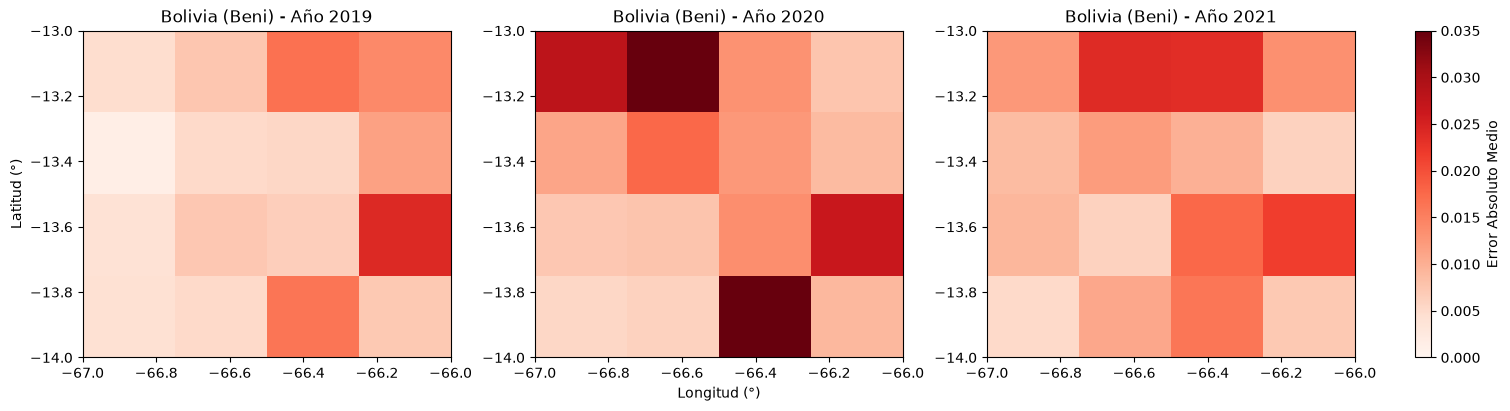

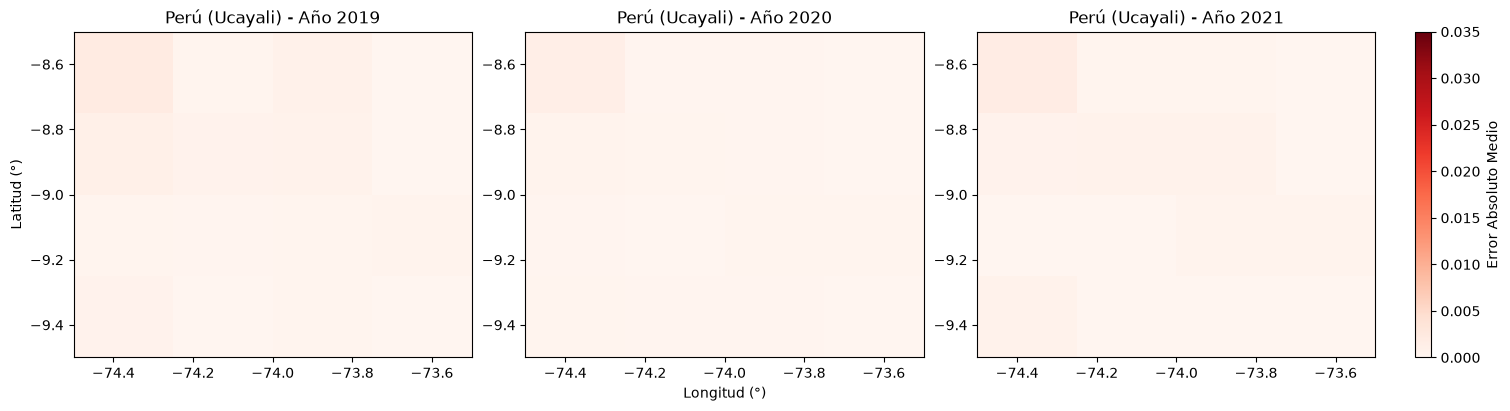

In [7]:
# Con las funciones definidas se grafica el error anual para cada región
plot_error_anual(bo_jja, "Bolivia (Beni)", vmin=0, vmax=0.035)
plot_error_anual(pe_jja, "Perú (Ucayali)", vmin=0, vmax=0.035)

La distribución espacial del error absoluto medio por año muestra las diferencias en la adecuación del modelo entre ambas regiones. En Bolivia priman tonalidades rojas intensas que representan errores medios cercanos a 0.035, con una concentración en el Este de la cuadrícula de estudio; lo cual indica desviaciones en la estimación de las áreas quemadas. Por el contrario, los mapas de Perú muestran una ausencia de tonalidades intensas, reflejando valores de error bajos en comparación a Bolivia. Ello confirma que el modelo mantiene una alta adecuación espacial en la región peruana, mientras que en el territorio boliviano presenta una mayor variabilidad y magnitud de error.

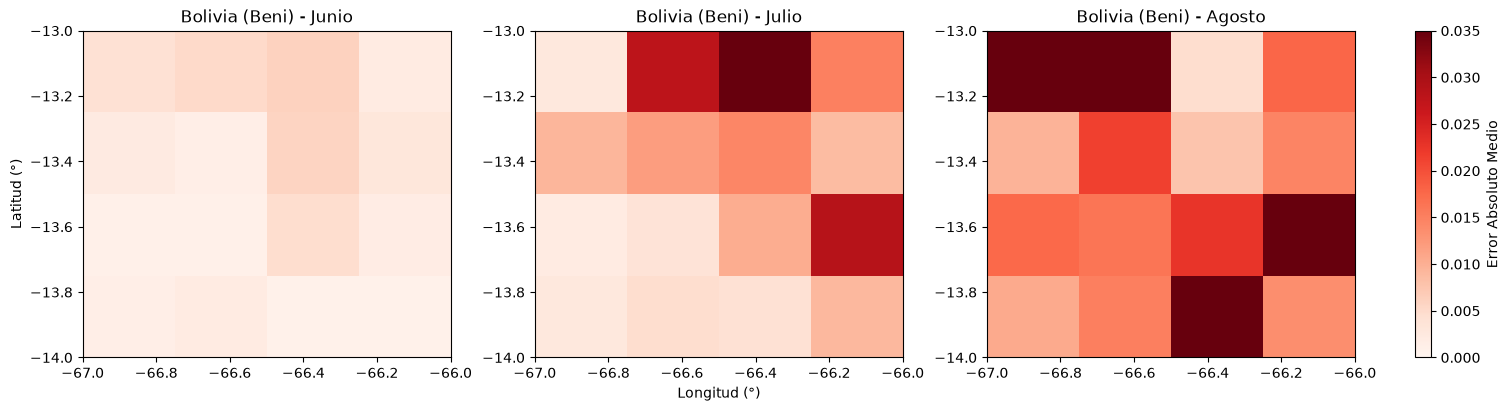

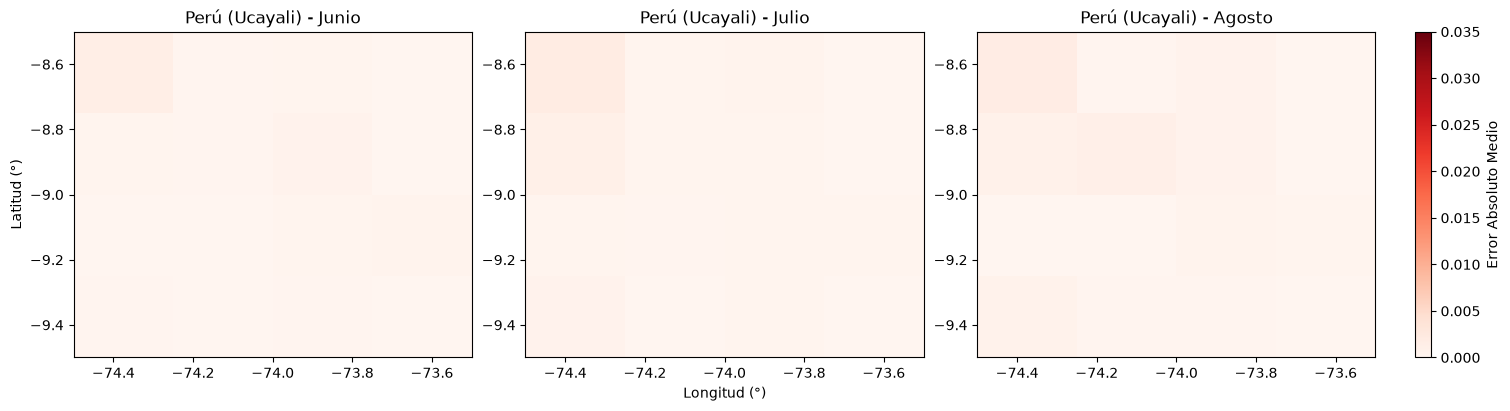

In [8]:
# Se grafica el error promedio por mes para cada región
plot_error_mensual(bo_jja, "Bolivia (Beni)", vmin=0, vmax=0.035)
plot_error_mensual(pe_jja, "Perú (Ucayali)", vmin=0, vmax=0.035)

También se evaluó el error absoluto medio a lo largo del trimestre. Se observa una evolución temporal en la magnitud de las variaciones según la región. En Bolivia, el error incrementa conforme avanzan los meses: se evidencian valores moderados en junio, se intensifica en julio por el Este y alcanza un máximo en agosto, donde los píxeles del Este y Sur registran tonalidades intensas. Por otro lado, el error de Perú se mantiene estable durante los tres meses, presentando valores de error bajos en el Oeste. Estos resultados muestran que la mayor fuente de error del modelo en Bolivia está relacioanda a la evolución temporal de incendios de junio a de agosto, mientras que en Ucayali el desempeño se mantiene preciso a lo largo de todo el periodo.

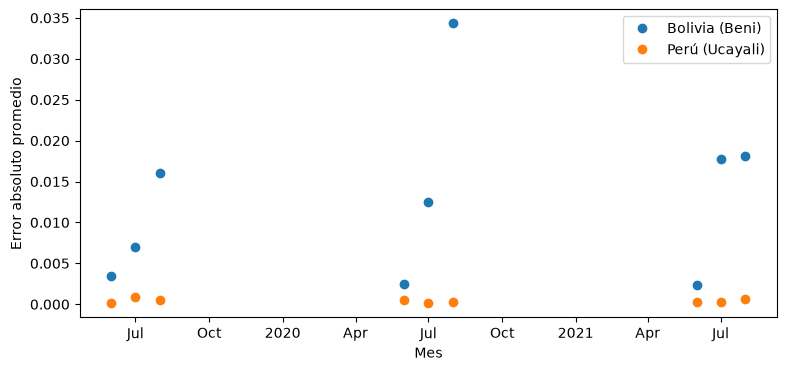

In [9]:
# Resumen gráfico del error promedio espacial por cada mes de datos
e_bo = abs(bo_jja["BAF_modelo"] - bo_jja["BAF_mapbiomas"])
e_pe = abs(pe_jja["BAF_modelo"] - pe_jja["BAF_mapbiomas"])

fig, ax = plt.subplots(figsize=(9, 4))

# Se grafica el error calculado resaltando solo los datos correspondientes para cada mes
e_bo.mean(("lat", "lon")).plot(
    ax=ax, marker="o", linestyle="none", label="Bolivia (Beni)"
)
e_pe.mean(("lat", "lon")).plot(
    ax=ax, marker="o", linestyle="none", label="Perú (Ucayali)"
)

ax.set_ylabel("Error absoluto promedio")
ax.set_xlabel("Mes")
ax.legend()
plt.savefig('distribuciónErrorEspacial.png',dpi=300, bbox_inches="tight")
plt.show()

Finalmente, al visualizar la serie temporal del error promedio espacial a lo largo de los meses, se confirma una diferencia en la magnitud y variabilidad entre ambas regiones. En Bolivia, el error muestra una alta dispersión temporal con tendencias mensuales opuestas: en 2019 el error decrece, mientras que en 2020 como en 2021 se invierte la tendencia y el error aumenta hacia el final del trimestre, con un máximo en agosto de 2021. Por el contrario, Perú mantiene una tendencia estable y cercana a cero durante todo el periodo analizado. Ello corrobora que la variabilidad del modelo en Bolivia es sensible a las condiciones de cada temporada, mientras que en Ucayali el desempeño es robusto a lo largo del tiempo. 